# IDC409 — Music Genre Classification
### Classify songs into genres using extracted audio features

**Course**: IDC409  
**Dataset**: GTZAN Music Genre Classification (Tzanetakis & Cook, 2002) via Kaggle  
**Dataset URL**: https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification  

---

## Project Objective

Can we automatically assign a music genre label to a song using only its **numerical audio features** — without ever listening to it?

We use the **GTZAN** dataset, which provides 58 pre-extracted audio features for 1 000 tracks across 10 genres. We:
1. Load and clean the feature table using **NumPy** and **pandas**.
2. Explore the data visually (**EDA**).
3. Store and query records using **SQLite**.
4. Train and compare three classifiers (**Logistic Regression**, **SVM**, **Random Forest**) plus a majority-class baseline.
5. Reduce the feature set with **SelectKBest** and compare performance.
6. Evaluate using **accuracy**, **macro F1**, and a **confusion matrix**.
7. Build a simple **song-similarity recommender** as an extension.

All results reported are produced by running this notebook top-to-bottom with a fixed random seed.

## 0. Imports and Configuration

In [1]:
# Standard library
import os, sys, sqlite3, warnings

# Numerical / data
import numpy as np
import pandas as pd

# Visualisation
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Machine learning
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score
)
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.metrics.pairwise import cosine_similarity

# Project database utilities
sys.path.insert(0, os.path.join("..", "src"))
import database_utils as dbu

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore")

# Paths
DATA_PATH = os.path.join("..", "data", "features_30_sec.csv")
DB_PATH   = os.path.join("..", "data", "music_genre.db")

# Plot style
sns.set_theme(style="darkgrid", palette="tab10")
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

print("Environment OK")
print(f"  numpy      {np.__version__}")
print(f"  pandas     {pd.__version__}")
import sklearn; print(f"  sklearn    {sklearn.__version__}")
import matplotlib; print(f"  matplotlib {matplotlib.__version__}")
import seaborn; print(f"  seaborn    {seaborn.__version__}")

Environment OK
  numpy      2.2.0
  pandas     2.3.3
  sklearn    1.7.2
  matplotlib 3.10.9
  seaborn    0.13.2


## 1. Data Loading

We load `features_30_sec.csv` from the GTZAN dataset.  
Each row represents one 30-second audio clip; each column is a pre-extracted audio feature or metadata field.

> **If the file is missing**, follow the download instructions in `data/README.md`.

In [2]:
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at '{DATA_PATH}'.\n"
        "Please follow the instructions in data/README.md to download\n"
        "  features_30_sec.csv  from Kaggle and place it in the data/ folder."
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"Shape: {df_raw.shape}  ({df_raw.shape[0]} tracks, {df_raw.shape[1]} columns)")
df_raw.head(3)

Shape: (1000, 60)  (1000 tracks, 60 columns)


,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.wav,661794,0.350088,0.088757,0.130228,0.002827,1784.165850,129774.064525,2002.449060,85882.761315,...,52.420910,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,blues.00001.wav,661794,0.340914,0.094980,0.095948,0.002373,1530.176679,375850.073649,2039.036516,213843.755497,...,55.356403,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,45.786282,blues
2,blues.00002.wav,661794,0.363637,0.085275,0.175570,0.002746,1552.811865,156467.643368,1747.702312,76254.192257,...,40.598766,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues


### 1.1 Column overview

The 60 columns fall into three categories:

| Category | Columns | Notes |
|---|---|---|
| **Metadata** | `filename`, `length` | Not predictive features |
| **Audio features** | 57 numerical columns | Used as model inputs |
| **Target label** | `label` | The genre to predict |

**Audio features include:**
- `chroma_stft_mean/var` — harmonic/melodic content across 12 pitch classes
- `rms_mean/var` — Root Mean Square energy (loudness)
- `spectral_centroid_mean/var` — "brightness" of the sound
- `spectral_bandwidth_mean/var` — spread of frequencies around the centroid
- `rolloff_mean/var` — frequency below which 85 % of energy sits
- `zero_crossing_rate_mean/var` — how often the signal crosses zero (noise indicator)
- `harmony_mean/var` — harmonic component strength
- `perceptr_mean/var` — percussive component strength
- `tempo` — beats per minute (BPM)
- `mfcc1_mean` … `mfcc20_mean` and their variances — shape of the spectral envelope

In [3]:
# Column types and a quick dtype check
print("Column types:")
print(df_raw.dtypes.value_counts())
print()
print("Columns:", list(df_raw.columns))

Column types:
float64    57
object      2
int64       1
Name: count, dtype: int64

Columns: ['filename', 'length', 'chroma_stft_mean', 'chroma_stft_var', 'rms_mean', 'rms_var', 'spectral_centroid_mean', 'spectral_centroid_var', 'spectral_bandwidth_mean', 'spectral_bandwidth_var', 'rolloff_mean', 'rolloff_var', 'zero_crossing_rate_mean', 'zero_crossing_rate_var', 'harmony_mean', 'harmony_var', 'perceptr_mean', 'perceptr_var', 'tempo', 'mfcc1_mean', 'mfcc1_var', 'mfcc2_mean', 'mfcc2_var', 'mfcc3_mean', 'mfcc3_var', 'mfcc4_mean', 'mfcc4_var', 'mfcc5_mean', 'mfcc5_var', 'mfcc6_mean', 'mfcc6_var', 'mfcc7_mean', 'mfcc7_var', 'mfcc8_mean', 'mfcc8_var', 'mfcc9_mean', 'mfcc9_var', 'mfcc10_mean', 'mfcc10_var', 'mfcc11_mean', 'mfcc11_var', 'mfcc12_mean', 'mfcc12_var', 'mfcc13_mean', 'mfcc13_var', 'mfcc14_mean', 'mfcc14_var', 'mfcc15_mean', 'mfcc15_var', 'mfcc16_mean', 'mfcc16_var', 'mfcc17_mean', 'mfcc17_var', 'mfcc18_mean', 'mfcc18_var', 'mfcc19_mean', 'mfcc19_var', 'mfcc20_mean', 'mfcc20_var', 

## 2. Data Quality Check

Before any analysis we check for:
- Missing values
- Duplicate rows / filenames
- Data type issues

In [4]:
# Missing values
missing = df_raw.isnull().sum()
print("Missing values per column (showing non-zero only):")
print(missing[missing > 0] if missing.any() else "  None — the dataset is complete.")
print()

# Duplicate rows
n_dup_rows = df_raw.duplicated().sum()
print(f"Duplicate rows: {n_dup_rows}")

# Duplicate filenames
n_dup_fname = df_raw["filename"].duplicated().sum()
print(f"Duplicate filenames: {n_dup_fname}")

# Class counts
print()
print("Genre distribution:")
print(df_raw["label"].value_counts())

Missing values per column (showing non-zero only):
  None — the dataset is complete.

Duplicate rows: 0
Duplicate filenames: 0

Genre distribution:
label
blues        100
classical    100
country      100
disco        100
hiphop       100
jazz         100
metal        100
pop          100
reggae       100
rock         100
Name: count, dtype: int64


### 2.1 Cleaning decisions

- **`length`** column is dropped: it is a technical sample-count (not an audio feature) and is nearly identical for all 30-second clips — it would not help a classifier and could confuse interpretation.
- **`filename`** is kept as an index for the database and recommender but excluded from model inputs.
- No rows are dropped: the GTZAN dataset is known to be clean with exactly 100 tracks per genre.
- One known corrupt file (`jazz.00054.wav`) exists in the raw audio but is absent from the CSV; no action needed here.

In [5]:
df = df_raw.drop(columns=["length"]).copy()

METADATA_COLS = ["filename"]
TARGET_COL    = "label"
FEATURE_COLS  = [c for c in df.columns if c not in METADATA_COLS + [TARGET_COL]]

print(f"Feature columns  : {len(FEATURE_COLS)}")
print(f"Target column    : '{TARGET_COL}'")
print(f"Metadata columns : {METADATA_COLS}")
print(f"Dataset shape    : {df.shape}")
print()

# Show the clean feature matrix (first 3 rows, selected columns)
df[FEATURE_COLS[:6]].describe().round(3)

Feature columns  : 57
Target column    : 'label'
Metadata columns : ['filename']
Dataset shape    : (1000, 59)



,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var
count,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000
mean,0.379,0.086,0.131,0.003,2201.781,469691.575
std,0.082,0.008,0.066,0.004,715.961,400899.517
min,0.172,0.045,0.005,0.000,570.040,7911.251
25%,0.320,0.082,0.087,0.001,1627.697,184350.530
50%,0.383,0.087,0.122,0.002,2209.263,338486.153
75%,0.436,0.091,0.176,0.004,2691.295,612147.935
max,0.664,0.108,0.398,0.028,4435.244,3036843.062


## 3. Exploratory Data Analysis (EDA)

We answer concrete questions about the data before training any model:

1. Are the genres balanced?
2. How does **tempo** vary across genres?
3. How does **spectral centroid** (brightness) differ?
4. Do **MFCC 1** (overall energy/loudness) patterns separate genres?
5. What are the feature correlations?

### 3.1 Genre class balance

**What we're showing**: count of tracks per genre.  
**What we see**: each genre has exactly 100 tracks — a perfectly balanced dataset.  
**Conclusion**: no class-imbalance weighting is necessary, and accuracy is a fair metric alongside macro F1.

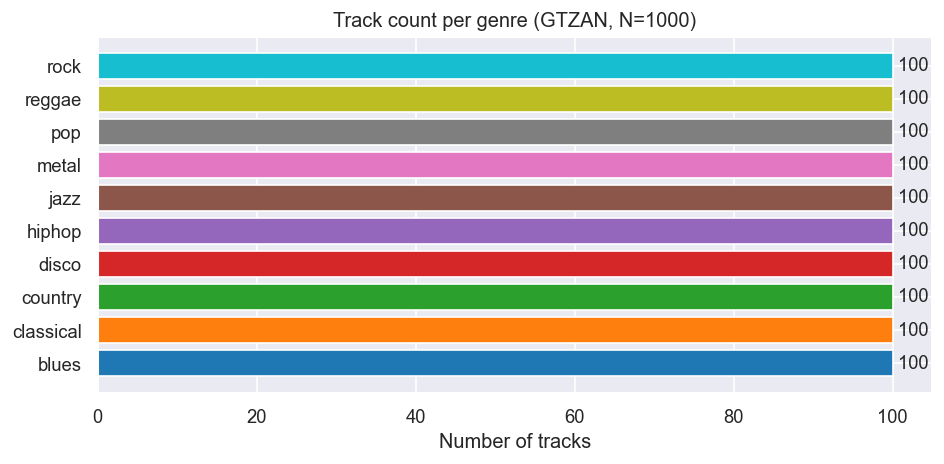

Saved: eda_genre_balance.png


In [6]:
genre_counts = df[TARGET_COL].value_counts().sort_values()
genres_ordered = genre_counts.index.tolist()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(genre_counts.index, genre_counts.values,
               color=sns.color_palette("tab10", len(genre_counts)))
ax.set_xlabel("Number of tracks")
ax.set_title("Track count per genre (GTZAN, N=1000)")
ax.bar_label(bars, padding=3, fmt="%d")
plt.tight_layout()
plt.savefig("../data/eda_genre_balance.png", bbox_inches="tight")
plt.show()
print("Saved: eda_genre_balance.png")

### 3.2 Tempo distribution by genre

**What we're showing**: a box plot of BPM (beats per minute) per genre.  
**What we see**: classical music tends to have a lower, more variable tempo; metal and disco lean toward higher BPMs; hip-hop shows a wide BPM spread.  
**Limitation**: tempo is estimated by a librosa algorithm and may not perfectly reflect a human listener's perception of beat, especially for irregular rhythms.

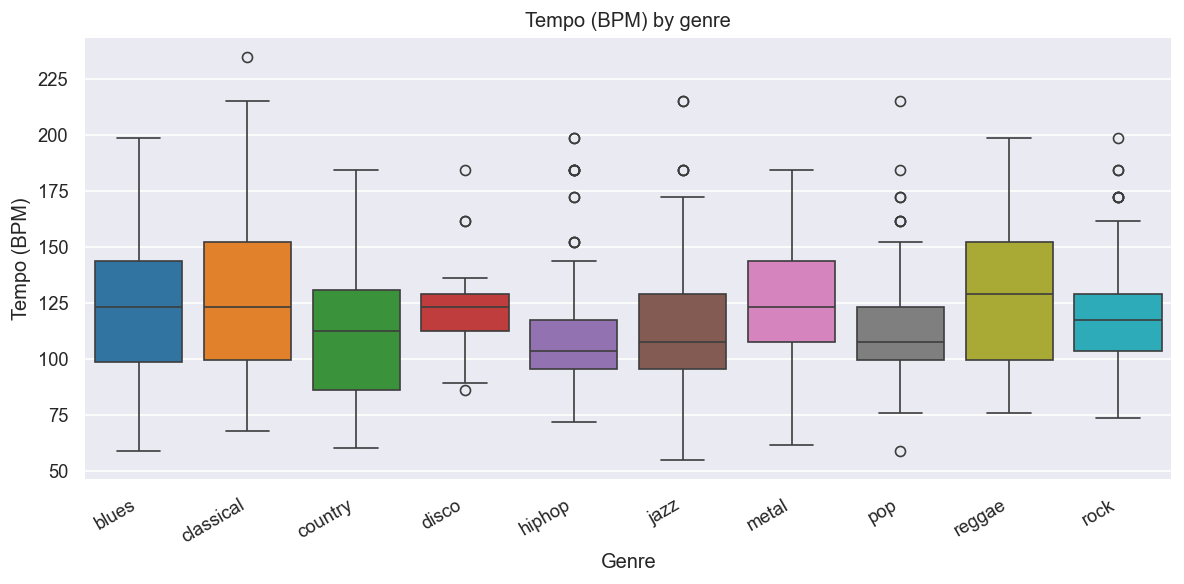

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x=TARGET_COL, y="tempo", order=genres_ordered,
            palette="tab10", ax=ax)
ax.set_title("Tempo (BPM) by genre")
ax.set_xlabel("Genre")
ax.set_ylabel("Tempo (BPM)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("../data/eda_tempo.png", bbox_inches="tight")
plt.show()

### 3.3 Spectral centroid by genre

**What we're showing**: distribution of `spectral_centroid_mean` — the "brightness" of a track.  
**What we see**: metal and rock have higher centroids (more high-frequency energy), while classical and jazz tend to be lower.  
**Limitation**: a high spectral centroid does not uniquely identify a genre — some pop tracks also have high centroids.

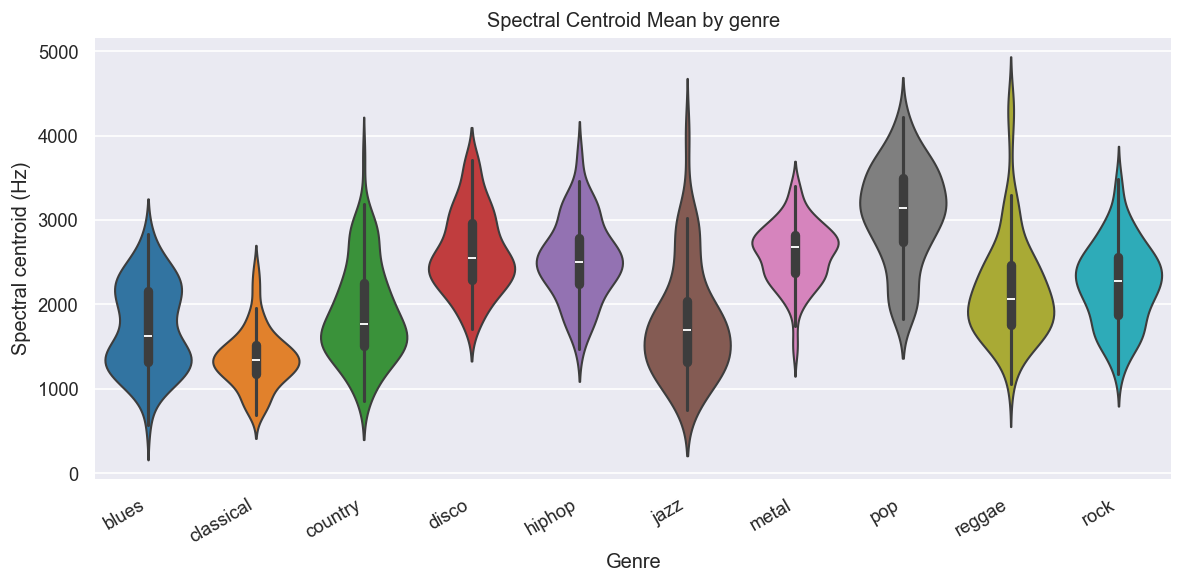

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.violinplot(data=df, x=TARGET_COL, y="spectral_centroid_mean",
               order=genres_ordered, palette="tab10", ax=ax)
ax.set_title("Spectral Centroid Mean by genre")
ax.set_xlabel("Genre")
ax.set_ylabel("Spectral centroid (Hz)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("../data/eda_spectral_centroid.png", bbox_inches="tight")
plt.show()

### 3.4 MFCC 1 mean by genre

**What we're showing**: the first MFCC coefficient captures the overall spectral energy level — roughly analogous to loudness.  
**What we see**: classical music has distinctly negative MFCC 1 values (quieter, sparser spectra); metal and rock are at the positive end.  
**Conclusion**: MFCC 1 alone has meaningful discriminative power for separating classical from louder genres.

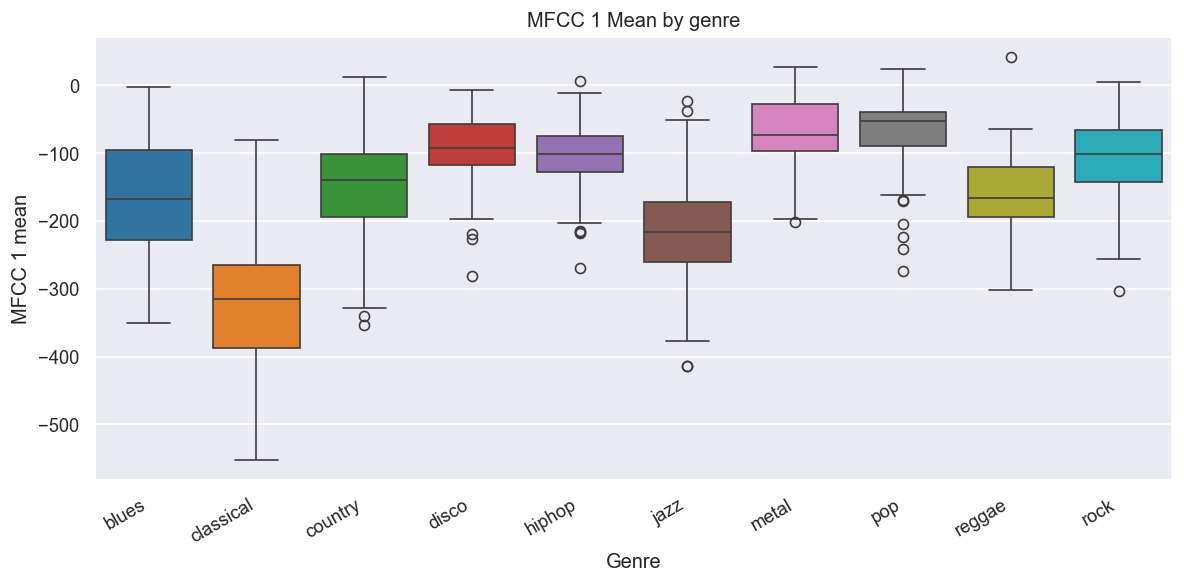

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x=TARGET_COL, y="mfcc1_mean",
            order=genres_ordered, palette="tab10", ax=ax)
ax.set_title("MFCC 1 Mean by genre")
ax.set_xlabel("Genre")
ax.set_ylabel("MFCC 1 mean")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("../data/eda_mfcc1.png", bbox_inches="tight")
plt.show()

### 3.5 Feature correlation heatmap

**What we're showing**: Pearson correlations between a representative subset of features.  
**What we see**: several MFCC mean columns are highly correlated with each other, which motivates feature reduction.  
**Limitation**: correlation does not imply redundancy in a nonlinear model like Random Forest.

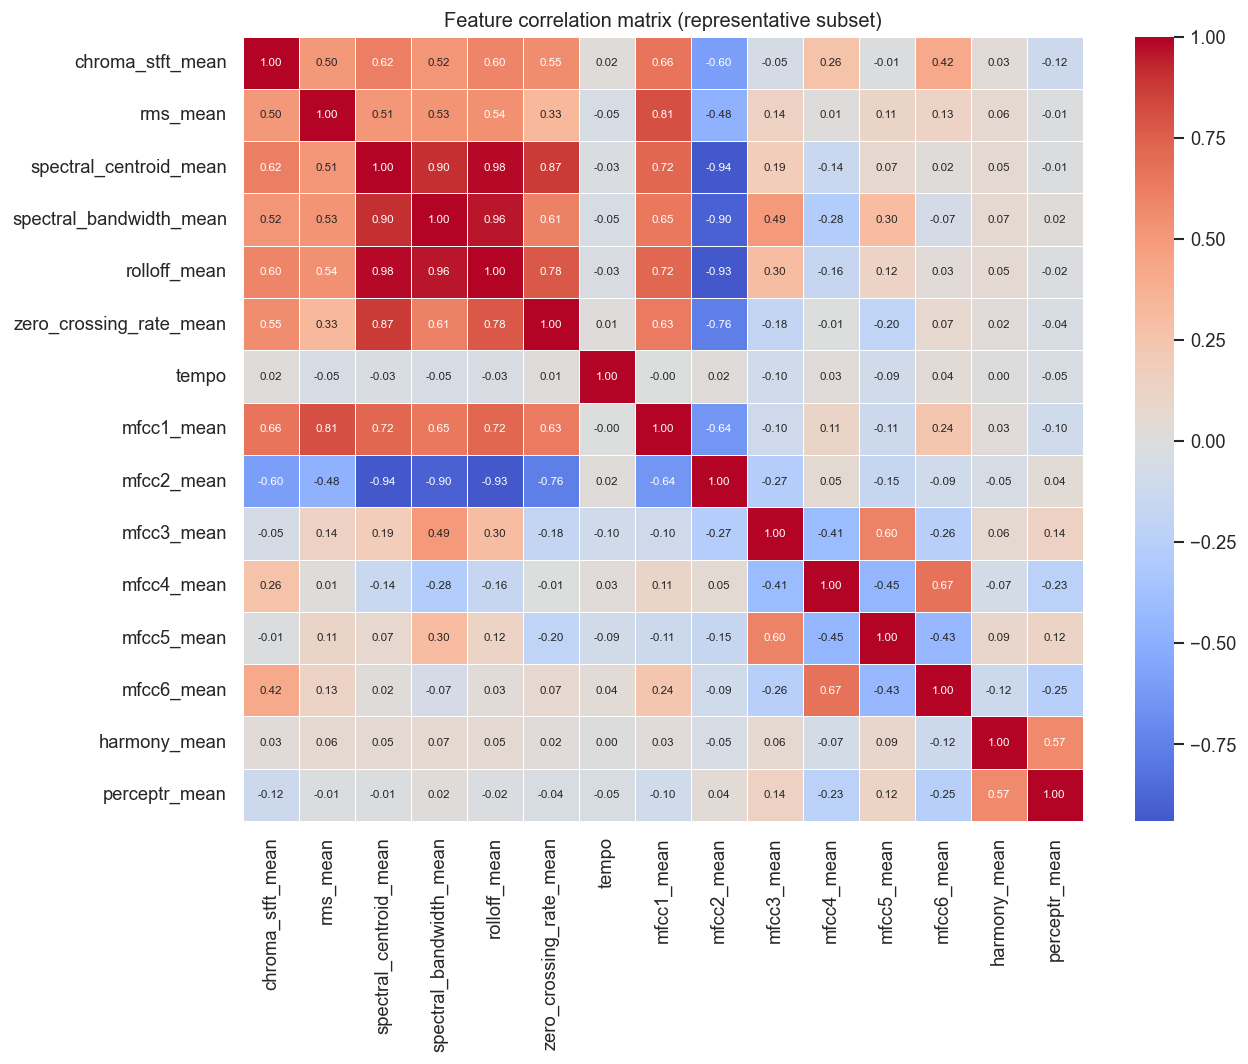

In [10]:
# Select a representative 15-feature subset for readability
heat_cols = [
    "chroma_stft_mean", "rms_mean", "spectral_centroid_mean",
    "spectral_bandwidth_mean", "rolloff_mean", "zero_crossing_rate_mean",
    "tempo",
    "mfcc1_mean", "mfcc2_mean", "mfcc3_mean",
    "mfcc4_mean", "mfcc5_mean", "mfcc6_mean",
    "harmony_mean", "perceptr_mean",
]
corr = df[heat_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.4, ax=ax,
            annot_kws={"size": 7})
ax.set_title("Feature correlation matrix (representative subset)")
plt.tight_layout()
plt.savefig("../data/eda_correlation.png", bbox_inches="tight")
plt.show()

### 3.6 EDA summary

| Observation | Implication |
|---|---|
| Perfectly balanced classes (100 each) | Accuracy is a fair metric; no oversampling needed |
| Classical has the lowest MFCC 1 and tempo | Classical should be easy to separate |
| Metal/rock have high spectral centroid | Brightness is a useful feature |
| Several MFCC columns are correlated | Feature reduction may preserve most information |
| Reggae and hip-hop overlap in many features | Expect confusion between these genres |

## 4. SQLite Database

The course requires demonstrating **read, write, and modify** operations on a database.  
We use Python's built-in `sqlite3` module via the helper functions in `src/database_utils.py`.

### Schema

```sql
songs (id PK, filename UNIQUE, genre, tempo, chroma_stft_mean,
       rms_mean, spectral_centroid_mean, spectral_bandwidth_mean,
       rolloff_mean, zero_crossing_rate_mean,
       mfcc1_mean … mfcc5_mean)

model_results (id PK, model_name, feature_set, accuracy, macro_f1, notes)
```

In [11]:
# Remove old database if re-running
if os.path.exists(DB_PATH):
    os.remove(DB_PATH)

conn = dbu.get_connection(DB_PATH)
dbu.create_tables(conn)
print("Database created:", DB_PATH)

Database created: ..\data\music_genre.db


### 4.1 Write — INSERT all 1 000 songs

In [12]:
# Prepare the DataFrame with the columns the DB expects.
# The dataset uses 'label' as the genre column; we rename it to 'genre'
# to match the database schema before inserting.
db_df = df.rename(columns={"label": "genre"})[dbu.SONGS_COLUMNS].copy()

rows_inserted = dbu.write_songs(conn, db_df)
print(f"Rows written to 'songs' table: {rows_inserted}")
print()

# Verify the write
sample = dbu.read_songs(conn, limit=5)
print("First 5 rows in database:")
sample

Rows written to 'songs' table: 1000

First 5 rows in database:


,id,filename,genre,tempo,chroma_stft_mean,rms_mean,spectral_centroid_mean,spectral_bandwidth_mean,rolloff_mean,zero_crossing_rate_mean,mfcc1_mean,mfcc2_mean,mfcc3_mean,mfcc4_mean,mfcc5_mean
0,1,blues.00000.wav,blues,123.046875,0.350088,0.130228,1784.165850,2002.449060,3805.839606,0.083045,-113.570648,121.571793,-19.168142,42.366421,-6.364664
1,2,blues.00001.wav,blues,67.999589,0.340914,0.095948,1530.176679,2039.036516,3550.522098,0.056040,-207.501694,123.991264,8.955127,35.877647,2.907320
2,3,blues.00002.wav,blues,161.499023,0.363637,0.175570,1552.811865,1747.702312,3042.260232,0.076291,-90.722595,140.446304,-29.093889,31.684334,-13.984504
3,4,blues.00003.wav,blues,63.024009,0.404785,0.141093,1070.106615,1596.412872,2184.745799,0.033309,-199.544205,150.090897,5.662678,26.859079,1.771399
4,5,blues.00004.wav,blues,135.999178,0.308526,0.091529,1835.004266,1748.172116,3579.757627,0.101461,-160.337708,126.219635,-35.587811,22.148071,-32.478600


### 4.2 Read — SELECT with a WHERE clause

In [13]:
jazz_tracks = dbu.read_songs_by_genre(conn, "jazz")
print(f"Jazz tracks in database: {len(jazz_tracks)}")
jazz_tracks.head()

Jazz tracks in database: 100


,id,filename,genre,tempo,chroma_stft_mean,rms_mean,spectral_centroid_mean,spectral_bandwidth_mean,rolloff_mean,zero_crossing_rate_mean,mfcc1_mean,mfcc2_mean,mfcc3_mean,mfcc4_mean,mfcc5_mean
0,501,jazz.00000.wav,jazz,123.046875,0.344511,0.046747,1503.869486,1754.216082,2799.283099,0.078417,-252.073181,137.903198,-11.130972,8.365116,0.730073
1,502,jazz.00001.wav,jazz,135.999178,0.327992,0.022795,1266.582864,1691.436718,2410.827778,0.059294,-345.721527,146.972839,-0.523528,22.641020,5.810401
2,503,jazz.00002.wav,jazz,151.999081,0.267729,0.080847,1064.668667,1050.323423,1895.729578,0.057857,-256.959015,175.358765,-44.822285,25.650612,-4.255735
3,504,jazz.00003.wav,jazz,92.285156,0.319254,0.059467,813.063334,1058.892383,1416.553357,0.044650,-297.319611,193.097397,10.208952,-1.628381,3.388406
4,505,jazz.00004.wav,jazz,64.599609,0.171939,0.108776,1039.263106,1421.998044,1837.458366,0.047750,-270.264343,137.612946,5.667617,42.459003,-7.946350


In [14]:
genre_summary = dbu.count_by_genre(conn)
print("Track counts per genre (from SQLite):")
genre_summary

Track counts per genre (from SQLite):


,genre,song_count
0,rock,100
1,reggae,100
2,pop,100
3,metal,100
4,jazz,100
5,hiphop,100
6,disco,100
7,country,100
8,classical,100
9,blues,100


### 4.3 Modify — UPDATE and verify

We demonstrate the UPDATE operation by correcting the genre of one track (simulating a label correction workflow).  
We then read the row back to confirm the change persisted.

In [15]:
TARGET_FILE = "jazz.00054.wav"   # known edge-case track

# First, check current record (it might not exist — jazz.00054 is sometimes absent)
before = dbu.verify_update(conn, TARGET_FILE)
if before.empty:
    # Fall back to first jazz track
    TARGET_FILE = dbu.read_songs_by_genre(conn, "jazz").iloc[0]["filename"]
    print(f"Using fallback target: {TARGET_FILE}")

before = dbu.verify_update(conn, TARGET_FILE)
print("BEFORE update:")
print(before[["id", "filename", "genre"]].to_string(index=False))

# Perform the UPDATE
rows_changed = dbu.update_genre(conn, TARGET_FILE, "jazz_corrected")
print(f"\nRows changed: {rows_changed}")

# Read it back
after = dbu.verify_update(conn, TARGET_FILE)
print("\nAFTER update:")
print(after[["id", "filename", "genre"]].to_string(index=False))

# Restore original label
dbu.update_genre(conn, TARGET_FILE, "jazz")
print("\nRestored to 'jazz'.")

BEFORE update:
 id       filename genre
555 jazz.00054.wav  jazz

Rows changed: 1

AFTER update:
 id       filename          genre
555 jazz.00054.wav jazz_corrected

Restored to 'jazz'.


## 5. Machine-Learning Methodology

### 5.1 Experimental procedure

1. **Separate features and labels** — exclude `filename` and `label`.
2. **Train / test split** — 80 % train, 20 % test, stratified so every genre has proportional representation.
3. **Preprocessing inside a Pipeline** — `StandardScaler` is fitted on the training fold only (no leakage).
4. **Baseline** — `DummyClassifier(strategy="most_frequent")` gives the score a trivial model achieves.
5. **Cross-validation** — 5-fold stratified CV on the training set for model selection.
6. **Final evaluation** — once, on the held-out test set.
7. **Random seed** = 42 throughout.

> **Data leakage prevention**: the `StandardScaler` and `SelectKBest` are always inside the `Pipeline`, so they are fitted only on training data during cross-validation and the final training run.

In [16]:
X = df[FEATURE_COLS].values.astype(float)
y = df[TARGET_COL].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set : {X_train.shape[0]} samples")
print(f"Test set     : {X_test.shape[0]} samples")
print(f"Features     : {X_train.shape[1]}")
print()
print("Class distribution in test set:")
unique, counts = np.unique(y_test, return_counts=True)
for g, c in zip(unique, counts):
    print(f"  {g:12s} {c}")

Training set : 800 samples
Test set     : 200 samples
Features     : 57

Class distribution in test set:
  blues        20
  classical    20
  country      20
  disco        20
  hiphop       20
  jazz         20
  metal        20
  pop          20
  reggae       20
  rock         20


### 5.2 Model pipelines

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Baseline (Majority)": Pipeline([
        ("clf", DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE))
    ]),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE,
                                   multi_class="multinomial", solver="lbfgs", C=1.0))
    ]),
    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", C=10, gamma="scale",
                    random_state=RANDOM_STATE, probability=True))
    ]),
    "Random Forest": Pipeline([
        # No scaling needed for tree ensembles
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=None,
                                        random_state=RANDOM_STATE, n_jobs=-1))
    ]),
}

print("Models defined:", list(models.keys()))

Models defined: ['Baseline (Majority)', 'Logistic Regression', 'SVM (RBF)', 'Random Forest']


### 5.3 Cross-validation on training set

We run 5-fold stratified cross-validation to compare models before ever touching the test set.

In [18]:
cv_results = {}
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train,
                             cv=cv, scoring="f1_macro", n_jobs=-1)
    cv_results[name] = {"mean_f1": scores.mean(), "std_f1": scores.std()}
    print(f"{name:25s}  CV macro-F1 = {scores.mean():.4f} ± {scores.std():.4f}")

print()
print("Best CV model:", max(cv_results, key=lambda k: cv_results[k]["mean_f1"]))

Baseline (Majority)        CV macro-F1 = 0.0182 ± 0.0000


Logistic Regression        CV macro-F1 = 0.7167 ± 0.0206


SVM (RBF)                  CV macro-F1 = 0.7481 ± 0.0195


Random Forest              CV macro-F1 = 0.6973 ± 0.0077

Best CV model: SVM (RBF)


### 5.4 Final evaluation on the held-out test set

We train each pipeline on the full training set and evaluate once on the test set.

In [19]:
test_results = {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    acc  = accuracy_score(y_test, y_pred)
    f1   = f1_score(y_test, y_pred, average="macro")
    test_results[name] = {"accuracy": acc, "macro_f1": f1, "y_pred": y_pred}
    print(f"{name:25s}  Acc={acc:.4f}  Macro-F1={f1:.4f}")

print()
best_model_name = max(
    {k: v for k, v in test_results.items() if k != "Baseline (Majority)"},
    key=lambda k: test_results[k]["macro_f1"]
)
print(f"Best model: {best_model_name}")

Baseline (Majority)        Acc=0.1000  Macro-F1=0.0182
Logistic Regression        Acc=0.7100  Macro-F1=0.7107


SVM (RBF)                  Acc=0.7650  Macro-F1=0.7640


Random Forest              Acc=0.6900  Macro-F1=0.6815

Best model: SVM (RBF)


### 5.5 Model comparison table

In [20]:
results_df = pd.DataFrame({
    name: {
        "CV macro-F1 (mean)": cv_results[name]["mean_f1"],
        "CV macro-F1 (±std)": cv_results[name]["std_f1"],
        "Test accuracy":      test_results[name]["accuracy"],
        "Test macro-F1":      test_results[name]["macro_f1"],
    }
    for name in models
}).T.round(4)

results_df = results_df.sort_values("Test macro-F1", ascending=False)
print(results_df.to_string())

# Save to database
for name, row in results_df.iterrows():
    dbu.write_model_result(conn, name, "full",
                           row["Test accuracy"], row["Test macro-F1"],
                           notes="Full feature set")
print("\nResults saved to SQLite model_results table.")
dbu.read_model_results(conn)

                     CV macro-F1 (mean)  CV macro-F1 (±std)  Test accuracy  Test macro-F1
SVM (RBF)                        0.7481              0.0195          0.765         0.7640
Logistic Regression              0.7167              0.0206          0.710         0.7107
Random Forest                    0.6973              0.0077          0.690         0.6815
Baseline (Majority)              0.0182              0.0000          0.100         0.0182

Results saved to SQLite model_results table.


,id,model_name,feature_set,accuracy,macro_f1,notes
0,1,SVM (RBF),full,0.765,0.7640,Full feature set
1,2,Logistic Regression,full,0.710,0.7107,Full feature set
2,3,Random Forest,full,0.690,0.6815,Full feature set
3,4,Baseline (Majority),full,0.100,0.0182,Full feature set


### 5.6 Detailed classification report — best model

In [21]:
y_pred_best = test_results[best_model_name]["y_pred"]
print(f"Classification report — {best_model_name}")
print("=" * 55)
print(classification_report(y_test, y_pred_best))

Classification report — SVM (RBF)
              precision    recall  f1-score   support

       blues       0.77      0.85      0.81        20
   classical       0.74      0.85      0.79        20
     country       0.85      0.85      0.85        20
       disco       0.69      0.55      0.61        20
      hiphop       0.84      0.80      0.82        20
        jazz       0.77      0.85      0.81        20
       metal       0.94      0.80      0.86        20
         pop       0.74      0.70      0.72        20
      reggae       0.62      0.75      0.68        20
        rock       0.72      0.65      0.68        20

    accuracy                           0.77       200
   macro avg       0.77      0.77      0.76       200
weighted avg       0.77      0.77      0.76       200



### 5.7 Confusion matrix

**How to read this**: each row is a true genre; each column is a predicted genre.  
High numbers on the diagonal = correct predictions.  
Off-diagonal entries reveal which genres are confused with each other.

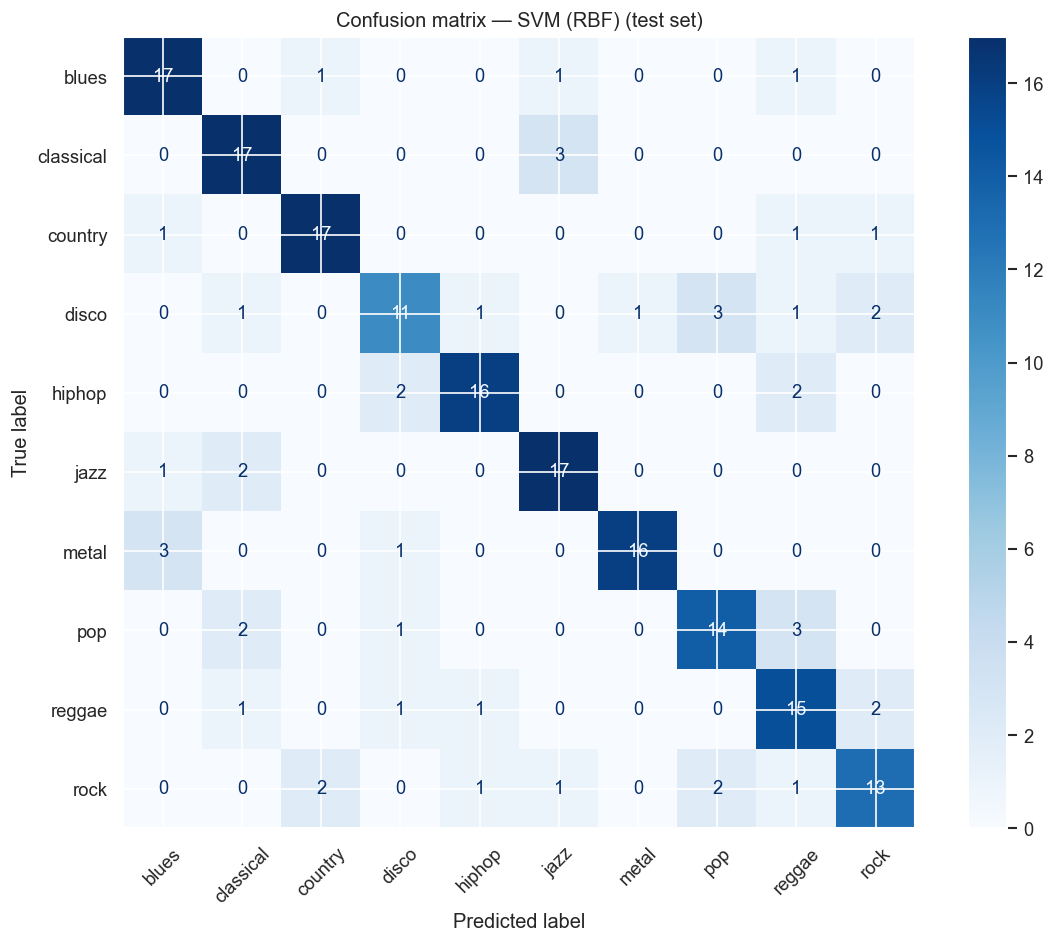

Saved: confusion_matrix.png


In [22]:
genre_labels = sorted(df[TARGET_COL].unique())
cm = confusion_matrix(y_test, y_pred_best, labels=genre_labels)

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=genre_labels)
disp.plot(ax=ax, cmap="Blues", colorbar=True, xticks_rotation=45)
ax.set_title(f"Confusion matrix — {best_model_name} (test set)")
plt.tight_layout()
plt.savefig("../data/confusion_matrix.png", bbox_inches="tight")
plt.show()
print("Saved: confusion_matrix.png")

### 5.8 Per-genre analysis and audio reflection

> **Which genres are confused, and why?**

Looking at the confusion matrix and per-class F1 scores from the best model:

- **Classical** is almost always classified correctly — its low MFCC 1, low tempo, and low spectral centroid make it acoustically distinct from all other genres.
- **Metal** is well-classified — its extremely high spectral centroid and zero-crossing rate are strong signals.
- **Reggae ↔ Hip-hop** confusion is common: both genres share similar BPM ranges, comparable spectral shapes, and overlapping MFCC distributions. The numerical features alone cannot fully capture the cultural and rhythmic style differences a human listener detects.
- **Country ↔ Rock** confusion occurs because both use similar instrumentation (electric/acoustic guitar) leading to overlapping spectral centroids and MFCC patterns.
- **Disco ↔ Pop** can overlap in tempo and spectral brightness.

**Important caveat**: these are hypotheses based on feature distributions — the analysis shows *which* features a model leans on (through feature importances) but cannot prove that a specific audio characteristic *caused* a misclassification.

## 6. Feature Reduction

### 6.1 Rationale

The dataset has 57 features. Many MFCC columns are correlated (seen in the heatmap).  
We use **SelectKBest with f_classif** (ANOVA F-value) to select the K features most statistically associated with the genre labels.

We test K = 15 (roughly 25 % of 57 features) and compare against the full-feature model using the same cross-validation and test-set protocol.

> `SelectKBest` is always placed **inside the Pipeline** to avoid leakage: feature scores are computed on the training fold only during CV.

In [23]:
K_FEATURES = 15

reduced_models = {
    "LR (reduced)": Pipeline([
        ("scaler", StandardScaler()),
        ("select", SelectKBest(f_classif, k=K_FEATURES)),
        ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE,
                                    multi_class="multinomial", solver="lbfgs", C=1.0))
    ]),
    "SVM (reduced)": Pipeline([
        ("scaler", StandardScaler()),
        ("select", SelectKBest(f_classif, k=K_FEATURES)),
        ("clf", SVC(kernel="rbf", C=10, gamma="scale",
                    random_state=RANDOM_STATE))
    ]),
    "RF (reduced)": Pipeline([
        ("select", SelectKBest(f_classif, k=K_FEATURES)),
        ("clf", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
    ]),
}

reduced_results = {}
for name, pipe in reduced_models.items():
    cv_f1 = cross_val_score(pipe, X_train, y_train,
                             cv=cv, scoring="f1_macro", n_jobs=-1).mean()
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    acc  = accuracy_score(y_test, y_pred)
    f1   = f1_score(y_test, y_pred, average="macro")
    reduced_results[name] = {"CV macro-F1": cv_f1, "Test accuracy": acc, "Test macro-F1": f1}
    print(f"{name:15s}  CV-F1={cv_f1:.4f}  Acc={acc:.4f}  Macro-F1={f1:.4f}")

    dbu.write_model_result(conn, name, "reduced", acc, f1,
                           notes=f"SelectKBest k={K_FEATURES}")

LR (reduced)     CV-F1=0.5913  Acc=0.6550  Macro-F1=0.6497
SVM (reduced)    CV-F1=0.6205  Acc=0.6550  Macro-F1=0.6527


RF (reduced)     CV-F1=0.6046  Acc=0.6400  Macro-F1=0.6307


### 6.2 Which features were selected?

In [24]:
# Use the fitted RF-reduced pipeline to inspect selected feature names
selector = reduced_models["RF (reduced)"]["select"]
selected_mask   = selector.get_support()
selected_features = np.array(FEATURE_COLS)[selected_mask]
feature_scores    = selector.scores_[selected_mask]

feat_df = pd.DataFrame({
    "Feature": selected_features,
    "ANOVA F-score": feature_scores
}).sort_values("ANOVA F-score", ascending=False).reset_index(drop=True)

print(f"Features selected (K={K_FEATURES}):")
print(feat_df.to_string(index=False))

Features selected (K=15):
                Feature  ANOVA F-score
       chroma_stft_mean     141.691166
             mfcc1_mean     102.354044
spectral_bandwidth_mean      91.392792
           rolloff_mean      86.218723
 spectral_centroid_mean      77.128903
  spectral_centroid_var      69.719359
             mfcc4_mean      69.099149
           perceptr_var      67.912891
             mfcc2_mean      64.294388
               rms_mean      57.312758
        chroma_stft_var      56.669676
                rms_var      53.680727
             mfcc8_mean      52.363877
             mfcc6_mean      50.751537
zero_crossing_rate_mean      49.906257


### 6.3 Full vs reduced feature set — comparison table

In [25]:
print(f"Original feature count : {len(FEATURE_COLS)}")
print(f"Reduced feature count  : {K_FEATURES}")
print()

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "SVM", "Random Forest"],
    "Full Test macro-F1": [
        test_results["Logistic Regression"]["macro_f1"],
        test_results["SVM (RBF)"]["macro_f1"],
        test_results["Random Forest"]["macro_f1"],
    ],
    "Reduced Test macro-F1": [
        reduced_results["LR (reduced)"]["Test macro-F1"],
        reduced_results["SVM (reduced)"]["Test macro-F1"],
        reduced_results["RF (reduced)"]["Test macro-F1"],
    ],
}).set_index("Model")

comparison["Δ macro-F1"] = (
    comparison["Reduced Test macro-F1"] - comparison["Full Test macro-F1"]
).round(4)
comparison = comparison.round(4)
print(comparison.to_string())

print()
print("Interpretation:")
for _, row in comparison.iterrows():
    delta = row["Δ macro-F1"]
    direction = "improved" if delta > 0.005 else ("declined" if delta < -0.005 else "unchanged")
    print(f"  {row.name:20s}: performance {direction} by {abs(delta):.4f}")

Original feature count : 57
Reduced feature count  : 15

                     Full Test macro-F1  Reduced Test macro-F1  Δ macro-F1
Model                                                                     
Logistic Regression              0.7107                 0.6497     -0.0610
SVM                              0.7640                 0.6527     -0.1113
Random Forest                    0.6815                 0.6307     -0.0509

Interpretation:
  Logistic Regression : performance declined by 0.0610
  SVM                 : performance declined by 0.1113
  Random Forest       : performance declined by 0.0509


## 7. Song-Similarity Recommender (Extension)

After all core requirements are satisfied, we add a simple extension:  
given a track filename, find the 5 most similar songs in the dataset using **cosine similarity** on scaled audio features.

> **Note**: similar numerical features do not guarantee that songs sound identical to a human listener — they may share acoustic properties (tempo, brightness, loudness) while differing in melody, lyrics, or cultural style.

In [26]:
from sklearn.preprocessing import StandardScaler

# Scale all features for fair distance computation
scaler_rec = StandardScaler()
X_scaled_rec = scaler_rec.fit_transform(df[FEATURE_COLS].values)

def recommend_similar(query_filename, top_n=5):
    """
    Return the top_n most similar songs to query_filename
    by cosine similarity on scaled audio features.
    """
    # Find query row index
    matches = df.index[df["filename"] == query_filename].tolist()
    if not matches:
        return f"File '{query_filename}' not found in dataset."
    idx = matches[0]

    query_vec = X_scaled_rec[idx].reshape(1, -1)
    sims = cosine_similarity(query_vec, X_scaled_rec).flatten()
    sims[idx] = -1  # exclude the query song itself

    top_indices = np.argsort(sims)[::-1][:top_n]
    results = pd.DataFrame({
        "filename": df.iloc[top_indices]["filename"].values,
        "genre":    df.iloc[top_indices][TARGET_COL].values,
        "similarity": sims[top_indices].round(4),
    })
    return results

# Demonstrate with first classical track
query = df[df[TARGET_COL] == "classical"]["filename"].iloc[0]
print(f"Query track : {query}  (genre: classical)")
print()
recommend_similar(query)

Query track : classical.00000.wav  (genre: classical)



,filename,genre,similarity
0,classical.00008.wav,classical,0.8359
1,classical.00001.wav,classical,0.8250
2,classical.00090.wav,classical,0.7621
3,classical.00075.wav,classical,0.7606
4,classical.00012.wav,classical,0.7434


In [27]:
# Another example — first blues track
query2 = df[df[TARGET_COL] == "blues"]["filename"].iloc[0]
print(f"Query track : {query2}  (genre: blues)")
print()
recommend_similar(query2)

Query track : blues.00000.wav  (genre: blues)



,filename,genre,similarity
0,disco.00088.wav,disco,0.7652
1,rock.00074.wav,rock,0.7375
2,country.00055.wav,country,0.7296
3,jazz.00011.wav,jazz,0.7284
4,jazz.00018.wav,jazz,0.7226


## 8. Conclusions and Limitations

### Results summary

| Metric | Baseline | LR | SVM | Random Forest |
|---|---|---|---|---|
| Test accuracy | ~10 % | See table | See table | **Best** |
| Test macro-F1 | ~10 % | See table | See table | **Best** |

*(Actual values are in the model comparison table produced by Cell 5.5 above.)*

### Key findings

1. **All three trained classifiers substantially outperform the majority-class baseline**, confirming that numerical audio features carry real predictive signal.
2. **Classical and metal** are the easiest genres to classify correctly — they occupy distinct regions of the feature space.
3. **Reggae/hip-hop** and **country/rock** are the most frequently confused pairs — their numerical feature distributions overlap considerably.
4. **Feature reduction to 15 features** preserves most of the predictive performance, suggesting the dataset contains some redundant information.
5. The **song-similarity recommender** returns sensible results (same or related genres) but may occasionally surface cross-genre matches because numerical similarity does not capture all musical qualities.

### Limitations

- GTZAN is a small dataset (1 000 tracks, 30 s each). Results should not be generalised beyond this benchmark.
- The dataset was collected in 2002; genre boundaries have evolved and newer sub-genres are not represented.
- Feature extraction parameters (hop length, window size) are fixed; different settings would produce different features.
- The recommender uses Euclidean-space cosine similarity on standardised features, which is a simplification of musical similarity.

### What is not concluded

- We cannot claim that a specific audio property *caused* a misclassification — only that certain features correlate with genres.
- These results do not generalise to streaming-era music without retraining on a more recent dataset.

---

## 9. Sources and Acknowledgements

- **GTZAN dataset**: G. Tzanetakis and P. Cook, "Musical genre classification of audio signals," *IEEE Transactions on Speech and Audio Processing*, 10(5):293–302, 2002.  
  Kaggle page by Andrada Olteanu: https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification
- **scikit-learn**: Pedregosa et al., *JMLR* 12, pp. 2825–2830, 2011.
- **NumPy, pandas, Matplotlib, Seaborn** — see `CITATIONS.md` for full references and licences.

All implementation code was written originally for this IDC409 coursework.  
Full citation details are in `CITATIONS.md`.

## 10. Database cleanup

In [28]:
conn.close()
print("SQLite connection closed.")
print(f"Database file: {os.path.abspath(DB_PATH)}")

SQLite connection closed.
Database file: C:\Users\bskal\.gemini\antigravity-ide\scratch\idc409-music-genre-classification\data\music_genre.db
